# THEMIS Plasma Density — Machine Learning Analysis (v3)

Builds on the extended multi-probe notebook, with fixes and upgrades:

**Bug fixes**
- **`scpot2dens` was silently never used in v2.** It returns a *single* density array, but v2 unpacked it into two variables (`ne_scpot, ni_scpot = ...`), which raises `ValueError` and always fell into the `except` fallback — so `ne_scpot` was just a copy of the ESA density. Fixed, and `scpot2dens_nishimura` added as a second, independent estimate.

**Methodology fixes (honest evaluation)**
- **Removed target leakage from the supervised features.** v2 used `ne_lag1`, `ne_lag2`, `log_ni` and `ni_over_ne` as inputs to predict `ne`. Lagged copies of the target make the task near-trivial persistence forecasting, and in a quasi-neutral plasma `ni ≈ ne`, so `log_ni` is essentially the answer key. The models now use only *physically independent* drivers (spacecraft potential, Te, vth, |B|, position, solar-wind conditions). A **persistence baseline** is still reported separately so you can see what the lag features were really doing.
- **Target is `log10(ne)`.** Density spans ~4 orders of magnitude; regressing raw `ne` lets a handful of high-density points dominate R² and RMSE.
- **Time-aware cross-validation.** `GridSearchCV` now uses `TimeSeriesSplit` instead of shuffled K-fold, so hyperparameters aren't tuned with information from the future.
- **Leave-one-probe-out validation** — train on 4 probes, test on the 5th. This directly answers "do models generalise across spacecraft?", which v2 asked but never tested.
- **Classification thresholds computed on the training set only** (v2 computed the 33/66 percentiles on the full dataset, leaking test statistics).

**New physics content**
- **OMNI solar-wind drivers** (IMF Bz, flow speed, proton density, dynamic pressure, SYM-H) interpolated onto the spacecraft time base as leakage-free external features.
- **Derived plasma parameters** (electron beta, approximate MLT) for clustering and region interpretation.
- **Cluster → magnetospheric region mapping**: clusters plotted in the GSM X–Y plane and summarised per-cluster (median ne, Te, |B|, R, MLT) with heuristic region labels (plasmasphere, plasma sheet, lobe, magnetosheath).

**Practical**
- Data resampled to 30-s medians per probe (denoises spin-cadence moments and keeps grid searches tractable).

---
## 0 — Install & Imports

In [1]:
import sys, subprocess
subprocess.run([sys.executable, '-m', 'pip', 'install', 'pyspedas', 'minisom'], check=True)


[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip


CompletedProcess(args=['/opt/anaconda3/envs/pyspedas_conda_py312/bin/python', '-m', 'pip', 'install', 'pyspedas', 'minisom'], returncode=0)

In [2]:
import sys, subprocess
subprocess.run([sys.executable, '-m', 'pip', 'install', 'minisom'], check=True)


[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip


CompletedProcess(args=['/opt/anaconda3/envs/pyspedas_conda_py312/bin/python', '-m', 'pip', 'install', 'minisom'], returncode=0)

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

import pyspedas
from pyspedas import get_data
from pyspedas.projects.themis import scpot2dens, scpot2dens_nishimura

from sklearn.model_selection   import train_test_split, GridSearchCV, TimeSeriesSplit
from sklearn.preprocessing     import StandardScaler, label_binarize
from sklearn.pipeline          import Pipeline
from sklearn.metrics           import (
    r2_score, mean_squared_error, mean_absolute_error,
    accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, auc, classification_report
)
from sklearn.inspection        import permutation_importance
from sklearn.linear_model      import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.ensemble          import (RandomForestRegressor, GradientBoostingRegressor,
                                       RandomForestClassifier, GradientBoostingClassifier)
from sklearn.svm               import SVR, SVC
from sklearn.neighbors         import KNeighborsRegressor, KNeighborsClassifier
from sklearn.cluster           import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors         import NearestNeighbors
from sklearn.metrics           import silhouette_score, silhouette_samples

try:
    from minisom import MiniSom
    HAS_MINISOM = True
    print('MiniSom available.')
except ImportError:
    HAS_MINISOM = False
    print('MiniSom not available — SOM section will be skipped.')

RNG = 42
print('All imports successful.')

MiniSom available.
All imports successful.


---
## 1 — Data Loading: Multiple Probes, OMNI Solar Wind, Fixed `scpot2dens`

In [4]:
# ── Configuration ─────────────────────────────────────────────────────────────
TRANGE   = ['2007-07-20/00:00:00', '2007-07-20/23:59:59']
PROBES   = ['a', 'b', 'c', 'd', 'e']
RESAMPLE = '30s'          # median-resample cadence (denoise + tractable grid search)
RE_KM    = 6371.0

print(f'Time range : {TRANGE[0]}  →  {TRANGE[1]}')
print(f'Probes     : {PROBES}')
print(f'Resample   : {RESAMPLE} medians')

Time range : 2007-07-20/00:00:00  →  2007-07-20/23:59:59
Probes     : ['a', 'b', 'c', 'd', 'e']
Resample   : 30s medians


In [5]:
# ── Helpers ───────────────────────────────────────────────────────────────────
def safe_interp(t_src, y_src, t_ref):
    """Interpolate y_src onto t_ref; NaN-fill if source missing/empty."""
    if t_src is None or y_src is None or len(np.atleast_1d(t_src)) == 0:
        return np.full(len(t_ref), np.nan)
    y = np.asarray(y_src, dtype=float)
    good = np.isfinite(y)
    if good.sum() < 2:
        return np.full(len(t_ref), np.nan)
    out = np.interp(t_ref, np.asarray(t_src)[good], y[good],
                    left=np.nan, right=np.nan)
    return out

def make_pipeline(model):
    return Pipeline([('scaler', StandardScaler()), ('model', model)])

TSCV = TimeSeriesSplit(n_splits=5)   # time-aware CV for all grid searches
print('Helpers defined.')

Helpers defined.


In [6]:
# ── Load & process each probe ─────────────────────────────────────────────────
all_dfs = []

for P in PROBES:
    print(f'\n── Loading probe {P.upper()} ──')
    try:
        pyspedas.projects.themis.esa(
            trange=TRANGE, probe=P, level='l2', time_clip=True,
            varnames=[
                f'th{P}_peer_density',
                f'th{P}_peir_density',
                f'th{P}_peer_sc_pot',
                f'th{P}_peer_avgtemp',
                f'th{P}_peer_vthermal',
            ]
        )
        pyspedas.projects.themis.fgm(trange=TRANGE, probe=P, level='l2', time_clip=True)
        pyspedas.projects.themis.state(trange=TRANGE, probe=P, time_clip=True)

        ne_d  = get_data(f'th{P}_peer_density')
        ni_d  = get_data(f'th{P}_peir_density')
        sc_d  = get_data(f'th{P}_peer_sc_pot')
        te_d  = get_data(f'th{P}_peer_avgtemp')
        vth_d = get_data(f'th{P}_peer_vthermal')

        if ne_d is None:
            print(f'  Probe {P}: no electron density data — skipping.')
            continue

        t_ref = ne_d.times
        ne    = np.asarray(ne_d.y, dtype=float)

        ni_i    = safe_interp(ni_d.times,  ni_d.y,  t_ref) if ni_d  else np.full_like(ne, np.nan)
        scpot_i = safe_interp(sc_d.times,  sc_d.y,  t_ref) if sc_d  else np.full_like(ne, np.nan)
        Te_i    = safe_interp(te_d.times,  te_d.y,  t_ref) if te_d  else np.full_like(ne, np.nan)
        vth_i   = safe_interp(vth_d.times, vth_d.y, t_ref) if vth_d else np.full_like(ne, np.nan)

        # FGM |B|
        try:
            b_d  = get_data(f'th{P}_fgs_gsm')
            Bmag = np.linalg.norm(b_d.y, axis=1)
            B_i  = safe_interp(b_d.times, Bmag, t_ref)
        except Exception:
            B_i  = np.full_like(ne, np.nan)

        # Position: keep full GSM vector (in RE) — needed for MLT and region plots
        X_i = Y_i = Z_i = R_i = np.full_like(ne, np.nan)
        pos_d = None
        try:
            pos_d = get_data(f'th{P}_pos_gsm')
            if pos_d is not None and pos_d.y.ndim == 2:
                X_i = safe_interp(pos_d.times, pos_d.y[:, 0] / RE_KM, t_ref)
                Y_i = safe_interp(pos_d.times, pos_d.y[:, 1] / RE_KM, t_ref)
                Z_i = safe_interp(pos_d.times, pos_d.y[:, 2] / RE_KM, t_ref)
                R_i = np.sqrt(X_i**2 + Y_i**2 + Z_i**2)
        except Exception:
            pass

        # ── scpot2dens (FIXED: returns a single ndarray, not a tuple) ─────────
        ne_sp = np.full_like(ne, np.nan)
        try:
            dens = scpot2dens(
                scpot_i, t_ref,      # spacecraft potential + its time base
                Te_i,    t_ref,      # electron temperature
                ne,      t_ref,      # ESA electron density
                ni_i,    t_ref,      # ESA ion density
                P
            )
            if dens is not None:
                ne_sp = np.asarray(dens, dtype=float)
                print(f'  scpot2dens: {np.sum(np.isfinite(ne_sp))} valid pts')
            else:
                print('  scpot2dens returned None')
        except Exception as e:
            print(f'  scpot2dens failed: {e}')

        # ── scpot2dens_nishimura — independent second estimate ────────────────
        ne_nish = np.full_like(ne, np.nan)
        try:
            if pos_d is not None and vth_d is not None:
                dens_n = scpot2dens_nishimura(
                    scpot_i, t_ref,
                    vth_i,   t_ref,
                    ni_i,    t_ref,
                    pos_d.y, pos_d.times,
                    probe=P
                )
                if dens_n is not None:
                    ne_nish = np.asarray(dens_n, dtype=float)
                    print(f'  scpot2dens_nishimura: {np.sum(np.isfinite(ne_nish))} valid pts')
        except Exception as e:
            print(f'  scpot2dens_nishimura failed: {e}')

        probe_df = pd.DataFrame({
            'time'     : t_ref,
            'ne'       : ne,        # ESA electron density (target)
            'ne_scpot' : ne_sp,     # spacecraft-potential density (fixed)
            'ne_nish'  : ne_nish,   # Nishimura-formula density
            'ni'       : ni_i,
            'scpot'    : scpot_i,
            'Te'       : Te_i,
            'vth'      : vth_i,
            'B'        : B_i,
            'x_re'     : X_i,
            'y_re'     : Y_i,
            'z_re'     : Z_i,
            'R_re'     : R_i,
        })

        # Median-resample to RESAMPLE cadence (per probe, before any lags)
        probe_df['dt'] = pd.to_datetime(probe_df['time'], unit='s')
        probe_df = (probe_df.set_index('dt')
                            .resample(RESAMPLE).median()
                            .dropna(subset=['ne'])
                            .reset_index())
        probe_df['probe'] = P

        # Persistence lag (baseline only — NOT a model feature; see Section 1b)
        probe_df['ne_lag1'] = probe_df['ne'].shift(1)

        before = len(probe_df)
        core   = ['ne', 'scpot', 'Te', 'vth', 'B']
        probe_df.dropna(subset=core, inplace=True)
        probe_df.reset_index(drop=True, inplace=True)
        print(f'  Probe {P.upper()}: {before} → {len(probe_df)} pts after resampling & cleaning')
        all_dfs.append(probe_df)

    except Exception as e:
        print(f'  Probe {P.upper()} failed entirely: {e} — skipping.')

print(f'\nProbes loaded: {[d["probe"].iloc[0].upper() for d in all_dfs]}')

18-Jul-26 14:15:23: Downloading remote index: https://themis.ssl.berkeley.edu/data/themis/tha/l2/esa/2007/



── Loading probe A ──


18-Jul-26 14:15:24: File is current: /Users/admin-victor/spedas_data/themis/tha/l2/esa/2007/tha_l2_esa_20070720_v01.cdf
18-Jul-26 14:15:25: Downloading remote index: https://themis.ssl.berkeley.edu/data/themis/tha/l2/fgm/2007/
18-Jul-26 14:15:26: File is current: /Users/admin-victor/spedas_data/themis/tha/l2/fgm/2007/tha_l2_fgm_20070720_v01.cdf
18-Jul-26 14:15:27: File is current: /Users/admin-victor/spedas_data/themis/tha/l1/state/2007/tha_l1_state_20070720.cdf
18-Jul-26 14:15:27: Downloading remote index: https://themis.ssl.berkeley.edu/data/themis/thb/l2/esa/2007/


  scpot2dens: 28361 valid pts
  scpot2dens_nishimura: 0 valid pts
  Probe A: 2854 → 2846 pts after resampling & cleaning

── Loading probe B ──


18-Jul-26 14:15:28: File is current: /Users/admin-victor/spedas_data/themis/thb/l2/esa/2007/thb_l2_esa_20070720_v01.cdf
18-Jul-26 14:15:28: Downloading remote index: https://themis.ssl.berkeley.edu/data/themis/thb/l2/fgm/2007/
18-Jul-26 14:15:30: File is current: /Users/admin-victor/spedas_data/themis/thb/l2/fgm/2007/thb_l2_fgm_20070720_v01.cdf
18-Jul-26 14:15:31: File is current: /Users/admin-victor/spedas_data/themis/thb/l1/state/2007/thb_l1_state_20070720.cdf
18-Jul-26 14:15:31: Downloading remote index: https://themis.ssl.berkeley.edu/data/themis/thc/l2/esa/2007/


  scpot2dens: 28432 valid pts
  scpot2dens_nishimura: 0 valid pts
  Probe B: 2855 → 2845 pts after resampling & cleaning

── Loading probe C ──


... (2 outputs left out)

18-Jul-26 14:15:37: File is current: /Users/admin-victor/spedas_data/themis/thd/l2/esa/2007/thd_l2_esa_20070720_v01.cdf
18-Jul-26 14:15:37: Downloading remote index: https://themis.ssl.berkeley.edu/data/themis/thd/l2/fgm/2007/
18-Jul-26 14:15:38: File is current: /Users/admin-victor/spedas_data/themis/thd/l2/fgm/2007/thd_l2_fgm_20070720_v01.cdf
18-Jul-26 14:15:39: File is current: /Users/admin-victor/spedas_data/themis/thd/l1/state/2007/thd_l1_state_20070720.cdf
18-Jul-26 14:15:39: Downloading remote index: https://themis.ssl.berkeley.edu/data/themis/the/l2/esa/2007/


  scpot2dens: 28409 valid pts
  scpot2dens_nishimura: 17202 valid pts
  Probe D: 2857 → 2846 pts after resampling & cleaning

── Loading probe E ──


18-Jul-26 14:15:41: File is current: /Users/admin-victor/spedas_data/themis/the/l2/esa/2007/the_l2_esa_20070720_v01.cdf
18-Jul-26 14:15:41: Downloading remote index: https://themis.ssl.berkeley.edu/data/themis/the/l2/fgm/2007/
18-Jul-26 14:15:42: File is current: /Users/admin-victor/spedas_data/themis/the/l2/fgm/2007/the_l2_fgm_20070720_v01.cdf
18-Jul-26 14:15:43: File is current: /Users/admin-victor/spedas_data/themis/the/l1/state/2007/the_l1_state_20070720.cdf


  scpot2dens: 28400 valid pts
  scpot2dens_nishimura: 16076 valid pts
  Probe E: 2854 → 2854 pts after resampling & cleaning

Probes loaded: ['A', 'B', 'C', 'D', 'E']


In [7]:
# ── OMNI solar-wind drivers (external, leakage-free features) ─────────────────
omni_ok = False
try:
    pyspedas.projects.omni.data(trange=TRANGE, datatype='1min', time_clip=True)
    omni_vars = {
        'sw_bz'   : 'BZ_GSM',          # IMF Bz [nT]
        'sw_speed': 'flow_speed',      # solar wind speed [km/s]
        'sw_dens' : 'proton_density',  # solar wind density [cm^-3]
        'sw_pdyn' : 'Pressure',        # dynamic pressure [nPa]
        'sym_h'   : 'SYM_H',           # ring-current index [nT]
    }
    omni_data = {k: get_data(v) for k, v in omni_vars.items()}
    omni_ok = any(v is not None for v in omni_data.values())
    print('OMNI loaded:', [k for k, v in omni_data.items() if v is not None])
except Exception as e:
    print(f'OMNI load failed ({e}) — continuing without solar-wind features.')

for d in all_dfs:
    t = d['dt'].astype('int64') / 1e9    # back to unix seconds
    if omni_ok:
        for k, v in omni_data.items():
            d[k] = safe_interp(v.times, v.y, t.values) if v is not None else np.nan
    else:
        for k in ['sw_bz', 'sw_speed', 'sw_dens', 'sw_pdyn', 'sym_h']:
            d[k] = np.nan

18-Jul-26 14:15:43: Downloading remote index: https://spdf.gsfc.nasa.gov/pub/data/omni/omni_cdaweb/hro_1min/2007/
18-Jul-26 14:15:45: Downloading https://spdf.gsfc.nasa.gov/pub/data/omni/omni_cdaweb/hro_1min/2007/omni_hro_1min_20070701_v01.cdf to /Users/admin-victor/spedas_data/omni/hro_1min/2007/omni_hro_1min_20070701_v01.cdf
18-Jul-26 14:15:45: Download of /Users/admin-victor/spedas_data/omni/hro_1min/2007/omni_hro_1min_20070701_v01.cdf complete, 8.366 MB in 1.0 sec (8.217 MB/sec) (transfer_normal)


OMNI loaded: ['sw_bz', 'sw_speed', 'sw_dens', 'sw_pdyn', 'sym_h']


In [8]:
# ── Combine all probes ────────────────────────────────────────────────────────
df = pd.concat(all_dfs, ignore_index=True)
df.sort_values('dt', inplace=True)
df.reset_index(drop=True, inplace=True)
df['time'] = df['dt'].astype('int64') / 1e9

print(f'Combined dataset shape: {df.shape}')
print(f'Points per probe:')
print(df['probe'].value_counts().sort_index())
df.describe()

Combined dataset shape: (14218, 21)
Points per probe:
probe
a    2846
b    2845
c    2827
d    2846
e    2854
Name: count, dtype: int64


,dt,time,ne,ne_scpot,ne_nish,ni,scpot,Te,vth,B,x_re,y_re,z_re,R_re,ne_lag1,sw_bz,sw_speed,sw_dens,sw_pdyn,sym_h
count,14218,1.421800e+04,14218.000000,14218.000000,5828.000000,14216.000000,14218.000000,14218.000000,14218.000000,14218.000000,14208.000000,14208.000000,14208.000000,14208.000000,14216.000000,14203.000000,14143.000000,14143.000000,14143.000000,14213.000000
mean,2007-07-20 12:03:46.143620864,1.184933e+09,10.190994,1994.997043,10.767554,13.902624,3.269912,119.029868,5272.749899,709.081591,8.509569,0.564159,-2.517138,9.724739,10.193198,-0.867485,377.661328,13.848592,3.772728,-13.491240
min,2007-07-20 00:02:00,1.184890e+09,0.000900,0.035641,0.346627,0.000000,1.000000,7.890593,1666.016663,3.364948,-1.105598,-3.681360,-4.026121,1.100556,0.000900,-11.060000,309.600006,4.150000,1.320000,-43.000000
25%,2007-07-20 06:05:30,1.184912e+09,1.882615,9.957063,3.098053,0.921408,1.000000,25.769318,3010.756897,20.356516,5.572074,-2.606878,-3.645475,7.117044,1.882484,-3.440000,348.600006,6.720000,1.960000,-27.000000
50%,2007-07-20 12:04:30,1.184933e+09,7.220694,308.815171,6.620941,4.709010,2.491166,36.116797,3564.336914,50.156244,9.529060,0.025839,-3.178558,10.672110,7.232477,-0.430000,369.299988,7.870000,2.505000,-23.000000
75%,2007-07-20 18:02:52.500000,1.184955e+09,12.071607,4665.179541,15.928513,24.439149,4.962432,114.399061,6343.566589,115.400564,11.989931,4.036586,-1.583277,12.879793,12.072738,1.730000,418.899994,18.340000,4.760000,6.000000
max,2007-07-20 23:59:30,1.184976e+09,49.740931,4665.179541,39.963224,136.386917,19.490681,3369.189819,34425.998047,24790.459269,14.034560,4.498024,0.771909,14.631893,49.740931,9.870000,492.600006,63.720001,16.420000,26.000000
std,NaN,2.487998e+04,10.767335,2198.579138,10.467501,16.037286,2.522885,203.709422,3750.515063,2945.618230,4.176199,3.135802,1.441356,3.721126,10.767659,4.184825,44.137347,11.991383,3.067589,17.364543


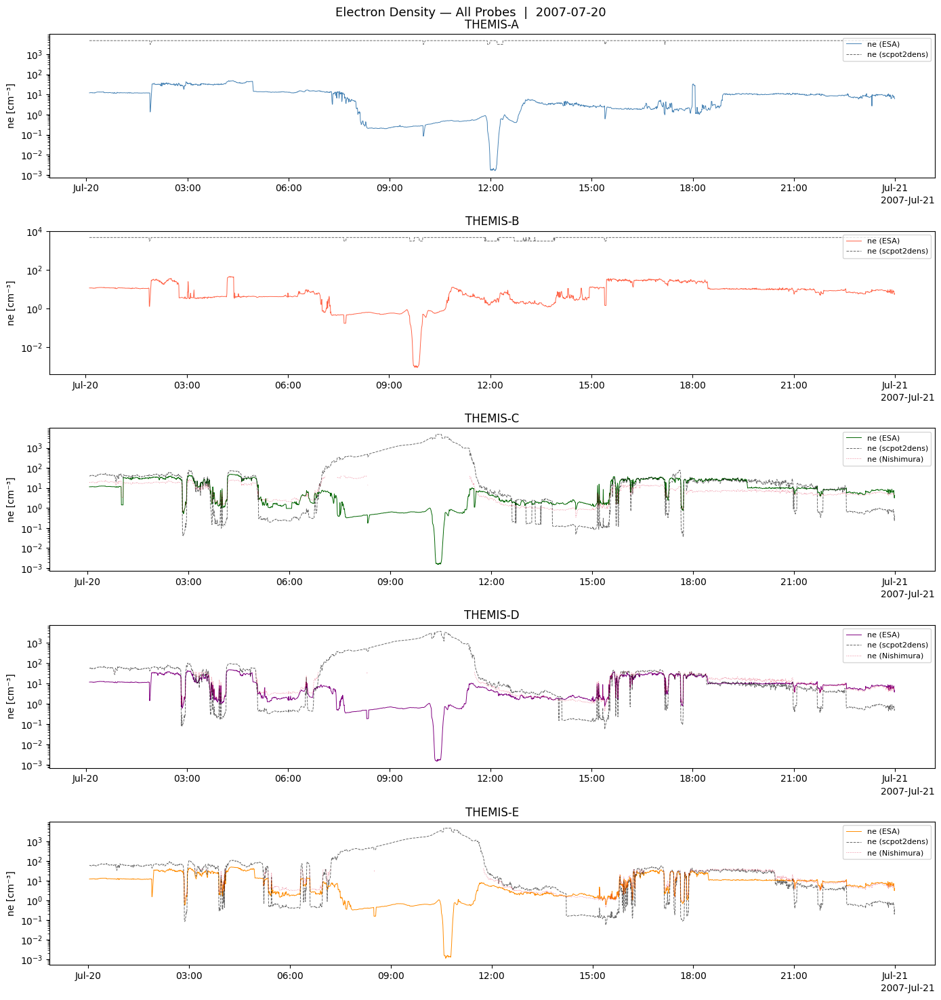

In [9]:
# ── Overview plot — one panel per probe ──────────────────────────────────────
probes_present = sorted(df['probe'].unique())
colors = {'a':'steelblue','b':'tomato','c':'darkgreen','d':'purple','e':'darkorange'}

fig, axes = plt.subplots(len(probes_present), 1,
                         figsize=(14, 3*len(probes_present)), sharex=False)
if len(probes_present) == 1:
    axes = [axes]

for ax, p in zip(axes, probes_present):
    sub = df[df['probe'] == p]
    ax.semilogy(sub['dt'], sub['ne'], lw=0.7, color=colors.get(p, 'gray'),
                label='ne (ESA)')
    if sub['ne_scpot'].notna().any():
        ax.semilogy(sub['dt'], sub['ne_scpot'], lw=0.7, color='black',
                    alpha=0.6, ls='--', label='ne (scpot2dens)')
    if sub['ne_nish'].notna().any():
        ax.semilogy(sub['dt'], sub['ne_nish'], lw=0.7, color='crimson',
                    alpha=0.5, ls=':', label='ne (Nishimura)')
    ax.set_ylabel('ne [cm⁻³]')
    ax.set_title(f'THEMIS-{p.upper()}')
    ax.legend(fontsize=8, loc='upper right')

fig.suptitle(f'Electron Density — All Probes  |  {TRANGE[0][:10]}', fontsize=13)
plt.tight_layout()
plt.show()

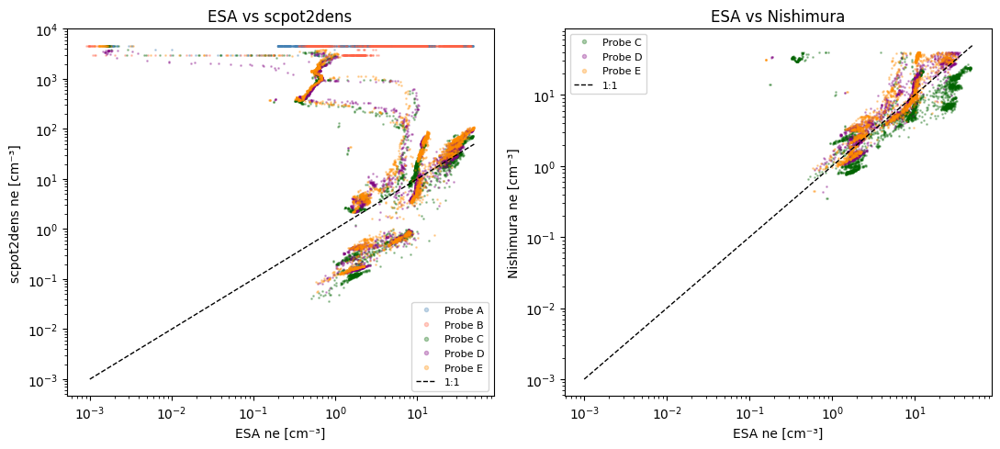

In [10]:
# ── ESA vs potential-derived densities (log–log) ──────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, col, name in [(axes[0], 'ne_scpot', 'scpot2dens'),
                      (axes[1], 'ne_nish',  'Nishimura')]:
    plotted = False
    for p in probes_present:
        sub  = df[df['probe'] == p]
        mask = np.isfinite(sub[col]) & np.isfinite(sub['ne']) & (sub[col] > 0) & (sub['ne'] > 0)
        if mask.sum() == 0:
            continue
        ax.loglog(sub.loc[mask, 'ne'], sub.loc[mask, col], '.',
                  ms=2, alpha=0.3, label=f'Probe {p.upper()}',
                  color=colors.get(p, 'gray'))
        plotted = True
    if plotted:
        lims = [max(df['ne'][df['ne'] > 0].min(), 1e-3), df['ne'].max()]
        ax.plot(lims, lims, 'k--', lw=1, label='1:1')
        ax.legend(markerscale=3, fontsize=8)
    else:
        ax.text(0.5, 0.5, f'no valid {name} data', ha='center', va='center',
                transform=ax.transAxes)
    ax.set_xlabel('ESA ne [cm⁻³]')
    ax.set_ylabel(f'{name} ne [cm⁻³]')
    ax.set_title(f'ESA vs {name}')
plt.tight_layout()
plt.show()

---
### 1b — Feature Engineering (and what we deliberately leave out)

The point of the regression is: *can independent plasma/field/solar-wind measurements
predict electron density?* That question is only meaningful if the features don't
already contain the answer:

| Dropped feature (v2) | Why it leaked |
|---|---|
| `ne_lag1`, `ne_lag2` | Lagged copies of the target. At 3-s cadence, `ne(t-1) ≈ ne(t)` — the model just learns persistence and every R² is inflated. |
| `log_ni`, `ni_over_ne` | Quasi-neutrality forces `ni ≈ ne`, so ion density from the *same instrument suite* is effectively the target under another name; `ni_over_ne` literally contains `ne`. |

The **persistence baseline** (`ne(t) = ne(t-1)`) is still computed and shown in the
league table — it tells you the score any lag-feature model would trivially reach,
and it's the number an honest model has to be judged against.

The target is **`log10(ne)`**: density spans ~4 decades, and in log space every
regime (lobe, plasma sheet, sheath) contributes to the loss instead of only the
densest points.

In [11]:
# ── Targets and leakage-free feature set ──────────────────────────────────────
df = df[df['ne'] > 0].copy()
df['log_ne'] = np.log10(df['ne'])

PHYS_FEATURES = ['scpot', 'Te', 'vth', 'B']
if df['R_re'].notna().sum() > 100:
    PHYS_FEATURES += ['R_re']
for f in ['sw_bz', 'sw_speed', 'sw_dens', 'sw_pdyn', 'sym_h']:
    if df[f].notna().sum() > 100:
        PHYS_FEATURES.append(f)

print(f'Leakage-free features ({len(PHYS_FEATURES)}): {PHYS_FEATURES}')
print(f'Target: log10(ne)  |  range: {df["log_ne"].min():.2f} … {df["log_ne"].max():.2f}')

Leakage-free features (10): ['scpot', 'Te', 'vth', 'B', 'R_re', 'sw_bz', 'sw_speed', 'sw_dens', 'sw_pdyn', 'sym_h']
Target: log10(ne)  |  range: -3.05 … 1.70


---
## 2 — Supervised Regression

Chronological 70/30 split (no shuffling), `TimeSeriesSplit` cross-validation inside
the grid search, target `log10(ne)`. Both the ESA density and the (now actually
computed) `scpot2dens` density are used as targets, so their predictability can be
compared fairly.

In [12]:
reg_models = {
    'Linear Regression': (make_pipeline(LinearRegression()), {}),
    'Ridge'            : (make_pipeline(Ridge()),
                          {'model__alpha': [0.01, 0.1, 1.0, 10.0, 100.0]}),
    'Lasso'            : (make_pipeline(Lasso(max_iter=5000)),
                          {'model__alpha': [0.001, 0.01, 0.1, 1.0]}),
    'kNN'              : (make_pipeline(KNeighborsRegressor()),
                          {'model__n_neighbors': [3, 5, 10, 15, 20],
                           'model__weights'    : ['uniform', 'distance']}),
    'Random Forest'    : (make_pipeline(RandomForestRegressor(random_state=RNG, n_jobs=-1)),
                          {'model__n_estimators': [100, 200],
                           'model__max_depth'   : [None, 5, 10],
                           'model__max_features': ['sqrt', 'log2']}),
    'Gradient Boosting': (make_pipeline(GradientBoostingRegressor(random_state=RNG)),
                          {'model__n_estimators' : [100, 200],
                           'model__learning_rate': [0.05, 0.1, 0.2],
                           'model__max_depth'    : [3, 5]}),
    'SVR'              : (make_pipeline(SVR()),
                          {'model__C'      : [0.1, 1.0, 10.0],
                           'model__epsilon': [0.01, 0.1, 0.5],
                           'model__kernel' : ['rbf']}),
}

In [13]:
def run_regression(target_col, label, log_target=False):
    """Train all models on target_col with chronological split + TimeSeriesSplit CV."""
    print(f'\n=== Regression target: {label} ===')
    work = df.copy()
    if log_target:
        work = work[work[target_col] > 0].copy()
        work['__y'] = np.log10(work[target_col])
    else:
        work['__y'] = work[target_col]

    valid = work[PHYS_FEATURES + ['__y', 'ne_lag1', target_col]].dropna(
        subset=PHYS_FEATURES + ['__y'])
    X = valid[PHYS_FEATURES].values
    y = valid['__y'].values

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.30, shuffle=False)
    print(f'Train: {X_train.shape[0]}  Test: {X_test.shape[0]}')

    results = []

    # Persistence baseline: predict y(t) with previous ne value
    lag = valid['ne_lag1'].values
    tgt = valid[target_col].values
    n_test = len(y_test)
    lag_test, tgt_test = lag[-n_test:], tgt[-n_test:]
    m = np.isfinite(lag_test) & np.isfinite(tgt_test) & (lag_test > 0)
    if log_target:
        r2_pers = r2_score(np.log10(tgt_test[m]), np.log10(lag_test[m]))
    else:
        r2_pers = r2_score(tgt_test[m], lag_test[m])
    results.append({'Model': 'Persistence (baseline)', 'R²': round(r2_pers, 4),
                    'RMSE': np.nan, 'MAE': np.nan,
                    '_model': None, '_y_pred': None, '_y_test': None})
    print(f'  {"Persistence baseline":<22} R²={r2_pers:.4f}   ← what lag features buy you')

    for name, (pipe, param_grid) in reg_models.items():
        if param_grid:
            gs = GridSearchCV(pipe, param_grid, cv=TSCV, scoring='r2',
                              n_jobs=-1, refit=True)
            gs.fit(X_train, y_train)
            best = gs.best_estimator_
        else:
            pipe.fit(X_train, y_train)
            best = pipe

        y_pred = best.predict(X_test)
        r2   = r2_score(y_test, y_pred)
        rmse = np.sqrt(mean_squared_error(y_test, y_pred))
        mae  = mean_absolute_error(y_test, y_pred)
        results.append({'Model': name, 'R²': round(r2, 4),
                        'RMSE': round(rmse, 4), 'MAE': round(mae, 4),
                        '_model': best, '_y_pred': y_pred,
                        '_y_test': y_test})
        print(f'  {name:<22} R²={r2:.4f}  RMSE={rmse:.4f} (log units)')

    return results, X_train, X_test, y_train, y_test

esa_results, X_train_e, X_test_e, y_train_e, y_test_e = run_regression(
    'ne', 'log10 ESA density', log_target=True)

if df['ne_scpot'].notna().sum() > 500:
    scpot_results, *_ = run_regression('ne_scpot', 'log10 scpot2dens density',
                                       log_target=True)
else:
    scpot_results = None
    print('\nToo few valid scpot2dens points — skipping that target.')


=== Regression target: log10 ESA density ===
Train: 9900  Test: 4243
  Persistence baseline   R²=0.9267   ← what lag features buy you
  Linear Regression      R²=-1.7866  RMSE=0.4798 (log units)


/opt/anaconda3/envs/pyspedas_conda_py312/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/envs/pyspedas_conda_py312/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/envs/pyspedas_conda_py312/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/envs

  Ridge                  R²=-1.7938  RMSE=0.4804 (log units)
  Lasso                  R²=-2.5365  RMSE=0.5405 (log units)


/opt/anaconda3/envs/pyspedas_conda_py312/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/envs/pyspedas_conda_py312/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/envs/pyspedas_conda_py312/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/envs

  kNN                    R²=-0.7974  RMSE=0.3853 (log units)


/opt/anaconda3/envs/pyspedas_conda_py312/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/envs/pyspedas_conda_py312/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/envs/pyspedas_conda_py312/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/envs

... (11 outputs left out)

/opt/anaconda3/envs/pyspedas_conda_py312/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/envs/pyspedas_conda_py312/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/envs/pyspedas_conda_py312/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/envs

  Gradient Boosting      R²=0.9865  RMSE=0.1739 (log units)


/opt/anaconda3/envs/pyspedas_conda_py312/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/envs/pyspedas_conda_py312/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/envs/pyspedas_conda_py312/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/envs

  SVR                    R²=0.9096  RMSE=0.4500 (log units)


In [14]:
# ── League tables ─────────────────────────────────────────────────────────────
def make_league(results, label):
    df_l = (pd.DataFrame(results)
              .drop(columns=['_model', '_y_pred', '_y_test'])
              .sort_values('R²', ascending=False)
              .reset_index(drop=True))
    df_l.index += 1
    df_l.columns = pd.MultiIndex.from_product([[label], df_l.columns])
    return df_l

print('\n' + '='*80)
print('   REGRESSION LEAGUE TABLE — chronological hold-out, log10 target')
print('='*80)
tables = [make_league(esa_results, 'ESA density')]
if scpot_results is not None:
    tables.append(make_league(scpot_results, 'scpot2dens'))
print(pd.concat(tables, axis=1).to_string())
print('='*80)
print('\nAny model that does not clearly beat the persistence baseline has not')
print('learned physics — it has learned autocorrelation.')


   REGRESSION LEAGUE TABLE — chronological hold-out, log10 target
              ESA density                                      scpot2dens                        
                    Model      R²    RMSE     MAE                   Model      R²    RMSE     MAE
1  Persistence (baseline)  0.9267     NaN     NaN       Gradient Boosting  0.9865  0.1739  0.0900
2           Random Forest -0.1243  0.3047  0.2595                     kNN  0.9822  0.1995  0.1153
3       Gradient Boosting -0.2629  0.3230  0.2727                   Lasso  0.9554  0.3161  0.2496
4                     kNN -0.7974  0.3853  0.3187       Linear Regression  0.9441  0.3538  0.2630
5       Linear Regression -1.7866  0.4798  0.4234                   Ridge  0.9392  0.3692  0.2757
6                   Ridge -1.7938  0.4804  0.4241           Random Forest  0.9172  0.4307  0.2534
7                   Lasso -2.5365  0.5405  0.4927                     SVR  0.9096  0.4500  0.2915
8                     SVR -3.3012  0.5960  0.4805  

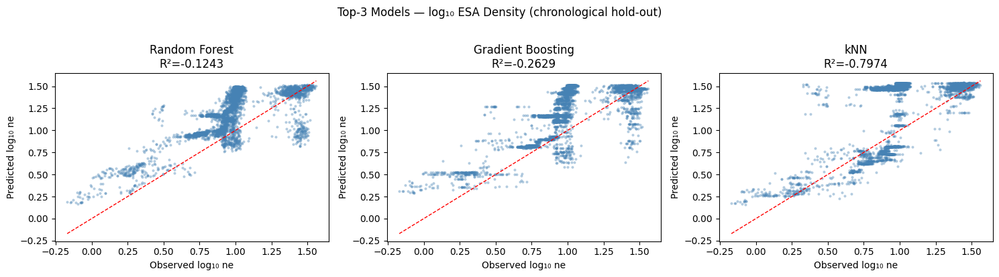

In [15]:
# ── Predicted vs actual — top 3 (ESA target, log space) ───────────────────────
trained = [r for r in esa_results if r['_model'] is not None]
top3 = sorted(trained, key=lambda r: -r['R²'])[:3]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, res in zip(axes, top3):
    yp, yt = res['_y_pred'], res['_y_test']
    ax.scatter(yt, yp, s=4, alpha=0.3, color='steelblue')
    lims = [min(yt.min(), yp.min()), max(yt.max(), yp.max())]
    ax.plot(lims, lims, 'r--', lw=1)
    ax.set_xlabel('Observed log₁₀ ne')
    ax.set_ylabel('Predicted log₁₀ ne')
    ax.set_title(f"{res['Model']}\nR²={res['R²']:.4f}")
plt.suptitle('Top-3 Models — log₁₀ ESA Density (chronological hold-out)', y=1.02)
plt.tight_layout()
plt.show()

In [16]:
# ── Leave-one-probe-out: does the model generalise across spacecraft? ─────────
best_name  = top3[0]['Model']
best_pipe, best_grid = reg_models[best_name]

valid_all = df[PHYS_FEATURES + ['log_ne', 'probe']].dropna()
lopo_rows = []
for held_out in probes_present:
    tr = valid_all[valid_all['probe'] != held_out]
    te = valid_all[valid_all['probe'] == held_out]
    if len(te) < 50:
        continue
    from sklearn.base import clone
    mdl = clone(best_pipe)
    mdl.fit(tr[PHYS_FEATURES].values, tr['log_ne'].values)
    yp = mdl.predict(te[PHYS_FEATURES].values)
    lopo_rows.append({
        'Held-out probe': held_out.upper(),
        'Train pts': len(tr), 'Test pts': len(te),
        'R²': round(r2_score(te['log_ne'], yp), 4),
        'RMSE (dex)': round(np.sqrt(mean_squared_error(te['log_ne'], yp)), 4),
    })

lopo_df = pd.DataFrame(lopo_rows)
print(f'Leave-one-probe-out — model: {best_name}\n')
print(lopo_df.to_string(index=False))
print('\nCompare with the chronological hold-out R² above: a large drop here')
print('means the model partly memorised probe-specific orbits/conditions')
print('rather than learning transferable plasma physics.')

18-Jul-26 14:16:42: /opt/anaconda3/envs/pyspedas_conda_py312/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(

18-Jul-26 14:16:42: /opt/anaconda3/envs/pyspedas_conda_py312/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(

18-Jul-26 14:16:42: /opt/anaconda3/envs/pyspedas_conda_py312/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thre

Leave-one-probe-out — model: Random Forest

Held-out probe  Train pts  Test pts     R²  RMSE (dex)
             A      11312      2831 0.7515      0.3641
             B      11313      2830 0.6730      0.3658
             C      11331      2812 0.9713      0.1205
             D      11312      2831 0.9729      0.1096
             E      11304      2839 0.9806      0.0955

Compare with the chronological hold-out R² above: a large drop here
means the model partly memorised probe-specific orbits/conditions
rather than learning transferable plasma physics.


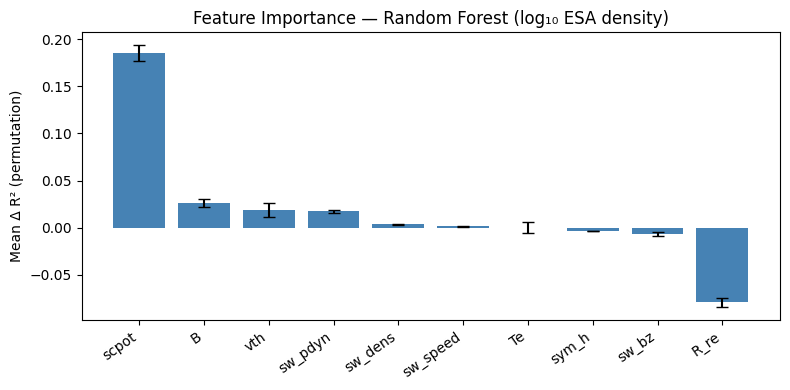

Expected physics: scpot should dominate (spacecraft potential is set by
the ambient electron flux, i.e. by density and temperature) — that is
exactly the relationship scpot2dens exploits analytically.


In [17]:
# ── Permutation feature importance (best ESA model) ───────────────────────────
best_esa = top3[0]
perm = permutation_importance(
    best_esa['_model'], X_test_e, y_test_e,
    n_repeats=20, random_state=RNG, scoring='r2')
sorted_idx = np.argsort(perm.importances_mean)[::-1]

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(range(len(PHYS_FEATURES)),
       perm.importances_mean[sorted_idx],
       yerr=perm.importances_std[sorted_idx],
       capsize=4, color='steelblue')
ax.set_xticks(range(len(PHYS_FEATURES)))
ax.set_xticklabels(np.array(PHYS_FEATURES)[sorted_idx], rotation=35, ha='right')
ax.set_ylabel('Mean Δ R² (permutation)')
ax.set_title(f"Feature Importance — {best_esa['Model']} (log₁₀ ESA density)")
plt.tight_layout()
plt.show()

print('Expected physics: scpot should dominate (spacecraft potential is set by')
print('the ambient electron flux, i.e. by density and temperature) — that is')
print('exactly the relationship scpot2dens exploits analytically.')

 N features      R²                          Features
          1 -1.6665                           [scpot]
          2 -0.2020                        [scpot, B]
          3 -0.4913                   [scpot, B, vth]
          4 -0.3530          [scpot, B, vth, sw_pdyn]
          5 -0.3985 [scpot, B, vth, sw_pdyn, sw_dens]


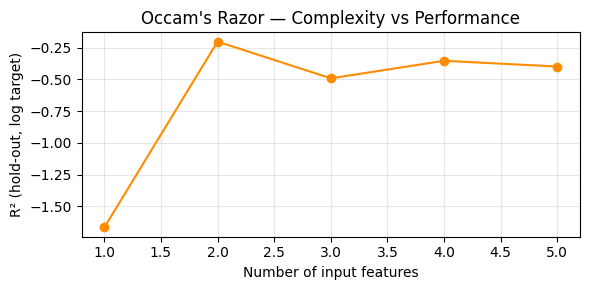

In [18]:
# ── Occam's razor — complexity vs performance ─────────────────────────────────
top_feats = list(np.array(PHYS_FEATURES)[sorted_idx])
occam_rows = []
for n in range(1, min(6, len(top_feats) + 1)):
    feats = top_feats[:n]
    idx   = [PHYS_FEATURES.index(f) for f in feats]
    sub   = make_pipeline(GradientBoostingRegressor(random_state=RNG))
    sub.fit(X_train_e[:, idx], y_train_e)
    yp = sub.predict(X_test_e[:, idx])
    occam_rows.append({'N features': n, 'Features': feats,
                       'R²': round(r2_score(y_test_e, yp), 4)})

occam_df = pd.DataFrame(occam_rows)
print(occam_df[['N features', 'R²', 'Features']].to_string(index=False))

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(occam_df['N features'], occam_df['R²'], 'o-', color='darkorange')
ax.set_xlabel('Number of input features')
ax.set_ylabel('R² (hold-out, log target)')
ax.set_title("Occam's Razor — Complexity vs Performance")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---
## 3 — Supervised Classification

Low / Medium / High density classes. Two fixes vs v2: class thresholds are computed
**from the training portion only** (computing percentiles on the full dataset leaks
test-set statistics into the labels), and the features are the same leakage-free set.

In [19]:
# ── Chronological split FIRST, then thresholds from the train portion ─────────
valid_c = df[PHYS_FEATURES + ['ne', 'log_ne']].dropna().reset_index(drop=True)
n_train = int(0.70 * len(valid_c))

q33, q66 = np.percentile(valid_c['ne'].values[:n_train], [33, 66])
print(f'Thresholds (train-only): low < {q33:.3f}  |  high > {q66:.3f}  [cm⁻³]')

y_all = np.where(valid_c['ne'] < q33, 0, np.where(valid_c['ne'] > q66, 2, 1))
CLASS_NAMES = ['Low', 'Medium', 'High']

X_clf = valid_c[PHYS_FEATURES].values
Xc_train, Xc_test = X_clf[:n_train], X_clf[n_train:]
yc_train, yc_test = y_all[:n_train], y_all[n_train:]
print(f'Train: {len(yc_train)}  |  Test: {len(yc_test)}')
print('Test-set class distribution:',
      dict(zip(CLASS_NAMES, np.bincount(yc_test, minlength=3))))

Thresholds (train-only): low < 1.813  |  high > 11.077  [cm⁻³]
Train: 9900  |  Test: 4243
Test-set class distribution: {'Low': np.int64(107), 'Medium': np.int64(3177), 'High': np.int64(959)}


In [20]:
clf_models = {
    'Logistic Regression': (
        make_pipeline(LogisticRegression(max_iter=1000)),
        {'model__C': [0.01, 0.1, 1.0, 10.0]}),
    'kNN': (
        make_pipeline(KNeighborsClassifier()),
        {'model__n_neighbors': [3, 5, 10, 15],
         'model__weights'    : ['uniform', 'distance']}),
    'Random Forest': (
        make_pipeline(RandomForestClassifier(random_state=RNG, n_jobs=-1)),
        {'model__n_estimators': [100, 200],
         'model__max_depth'   : [None, 5, 10]}),
    'Gradient Boosting': (
        make_pipeline(GradientBoostingClassifier(random_state=RNG)),
        {'model__n_estimators' : [100, 200],
         'model__learning_rate': [0.05, 0.1],
         'model__max_depth'    : [3, 5]}),
    'SVM': (
        make_pipeline(SVC(probability=True, random_state=RNG)),
        {'model__C'     : [0.1, 1.0, 10.0],
         'model__kernel': ['rbf']}),
}

clf_results = []
for name, (pipe, param_grid) in clf_models.items():
    gs = GridSearchCV(pipe, param_grid, cv=TSCV, scoring='accuracy',
                      n_jobs=-1, refit=True)
    gs.fit(Xc_train, yc_train)
    best = gs.best_estimator_

    yc_pred  = best.predict(Xc_test)
    yc_proba = best.predict_proba(Xc_test)
    acc = accuracy_score(yc_test, yc_pred)
    clf_results.append({'Model': name, 'Accuracy': round(acc, 4),
                        '_model': best, '_pred': yc_pred, '_proba': yc_proba})
    print(f'{name:<24} Accuracy={acc:.4f}')

clf_df = (pd.DataFrame(clf_results)
            .drop(columns=['_model', '_pred', '_proba'])
            .sort_values('Accuracy', ascending=False)
            .reset_index(drop=True))
clf_df.index += 1
print('\n' + '='*50)
print('   CLASSIFICATION LEAGUE TABLE')
print('='*50)
print(clf_df.to_string())
print('='*50)

Logistic Regression      Accuracy=0.2552
kNN                      Accuracy=0.5044
Random Forest            Accuracy=0.4073
Gradient Boosting        Accuracy=0.2729
SVM                      Accuracy=0.4061

   CLASSIFICATION LEAGUE TABLE
                 Model  Accuracy
1                  kNN    0.5044
2        Random Forest    0.4073
3                  SVM    0.4061
4    Gradient Boosting    0.2729
5  Logistic Regression    0.2552


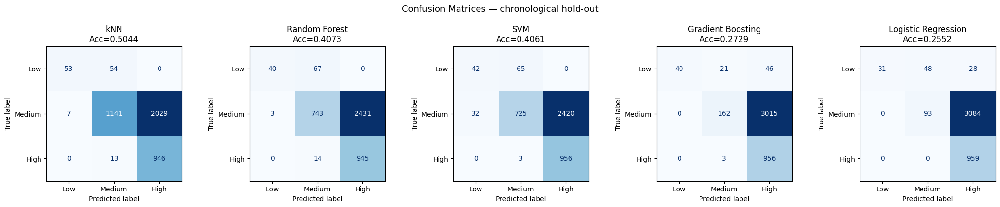

In [21]:
# ── Confusion matrices ────────────────────────────────────────────────────────
n_m = len(clf_results)
fig, axes = plt.subplots(1, n_m, figsize=(4.2*n_m, 4))
for ax, res in zip(axes, sorted(clf_results, key=lambda r: -r['Accuracy'])):
    cm   = confusion_matrix(yc_test, res['_pred'])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(f"{res['Model']}\nAcc={res['Accuracy']:.4f}")
plt.suptitle('Confusion Matrices — chronological hold-out', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

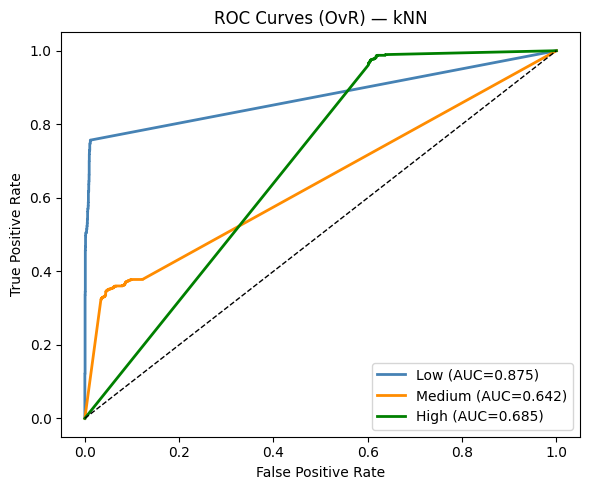


Classification Report — kNN

              precision    recall  f1-score   support

         Low       0.88      0.50      0.63       107
      Medium       0.94      0.36      0.52      3177
        High       0.32      0.99      0.48       959

    accuracy                           0.50      4243
   macro avg       0.72      0.61      0.55      4243
weighted avg       0.80      0.50      0.51      4243



In [22]:
# ── ROC curves (one-vs-rest) — best classifier ────────────────────────────────
best_clf = sorted(clf_results, key=lambda r: -r['Accuracy'])[0]
yc_bin   = label_binarize(yc_test, classes=[0, 1, 2])

fig, ax = plt.subplots(figsize=(6, 5))
for i, (cls, color) in enumerate(zip(CLASS_NAMES,
                                     ['steelblue', 'darkorange', 'green'])):
    fpr, tpr, _ = roc_curve(yc_bin[:, i], best_clf['_proba'][:, i])
    ax.plot(fpr, tpr, lw=2, color=color,
            label=f'{cls} (AUC={auc(fpr, tpr):.3f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1)
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title(f"ROC Curves (OvR) — {best_clf['Model']}")
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

print(f"\nClassification Report — {best_clf['Model']}\n")
print(classification_report(yc_test, best_clf['_pred'], target_names=CLASS_NAMES))

---
## 4 — Unsupervised Clustering → Magnetospheric Regions

Clustering may use anything (there is no target to leak), so density itself and
derived plasma parameters go in. New in v3:
- **Electron plasma beta** βₑ = 2μ₀·nₑkTₑ/B² — the classic discriminator between
  high-β (plasma sheet / sheath) and low-β (lobe / inner magnetosphere) regions.
- **DBSCAN eps chosen from a k-distance plot** rather than hard-coded.
- **Physical interpretation**: clusters plotted in the GSM X–Y plane and summarised
  by median plasma parameters with heuristic region labels.

In [23]:
# ── Derived plasma parameters ─────────────────────────────────────────────────
MU0, KB_EV = 4e-7*np.pi, 1.602176634e-19    # Te is in eV
ne_m3 = df['ne'] * 1e6                       # cm^-3 → m^-3
B_T   = df['B'] * 1e-9                       # nT → T
df['beta_e']     = (2 * MU0 * ne_m3 * df['Te'] * KB_EV) / (B_T**2)
df['log_beta_e'] = np.log10(df['beta_e'].clip(lower=1e-6))
# Approximate magnetic local time from GSM x,y (+x sunward = 12 MLT)
df['mlt'] = (np.degrees(np.arctan2(df['y_re'], df['x_re'])) / 15 + 12) % 24

CLUST_FEATURES = ['log_ne', 'Te', 'B', 'scpot', 'log_beta_e']
if 'R_re' in PHYS_FEATURES:
    CLUST_FEATURES.append('R_re')

df_clust  = df[CLUST_FEATURES + ['x_re', 'y_re', 'probe']].dropna().reset_index(drop=True)
scaler_c  = StandardScaler()
X_clust   = scaler_c.fit_transform(df_clust[CLUST_FEATURES].values)
print(f'Clustering matrix: {X_clust.shape}  |  features: {CLUST_FEATURES}')

# Silhouette is O(n²): score on a fixed subsample if large
rng = np.random.default_rng(RNG)
SIL_N   = min(5000, len(X_clust))
sil_idx = rng.choice(len(X_clust), SIL_N, replace=False)
def sil(X, labels):
    return silhouette_score(X[sil_idx], np.asarray(labels)[sil_idx])

Clustering matrix: (14208, 6)  |  features: ['log_ne', 'Te', 'B', 'scpot', 'log_beta_e', 'R_re']


In [24]:
# ── Silhouette sweep (K-Means) ────────────────────────────────────────────────
K_RANGE    = range(2, 9)
sil_scores, inertias = [], []
for k in K_RANGE:
    km  = KMeans(n_clusters=k, random_state=RNG, n_init=10)
    lbl = km.fit_predict(X_clust)
    s   = sil(X_clust, lbl)
    sil_scores.append(s)
    inertias.append(km.inertia_)
    print(f'k={k}  silhouette={s:.4f}  inertia={km.inertia_:.1f}')

K_OPT = list(K_RANGE)[int(np.argmax(sil_scores))]
print(f'\n→ Optimal k = {K_OPT}  (max silhouette = {max(sil_scores):.4f})')

k=2  silhouette=0.4416  inertia=53741.7
k=3  silhouette=0.4305  inertia=39182.1
k=4  silhouette=0.4736  inertia=29424.2
k=5  silhouette=0.4630  inertia=22955.9
k=6  silhouette=0.4449  inertia=19277.1
k=7  silhouette=0.4148  inertia=16194.6
k=8  silhouette=0.4206  inertia=14219.0

→ Optimal k = 4  (max silhouette = 0.4736)


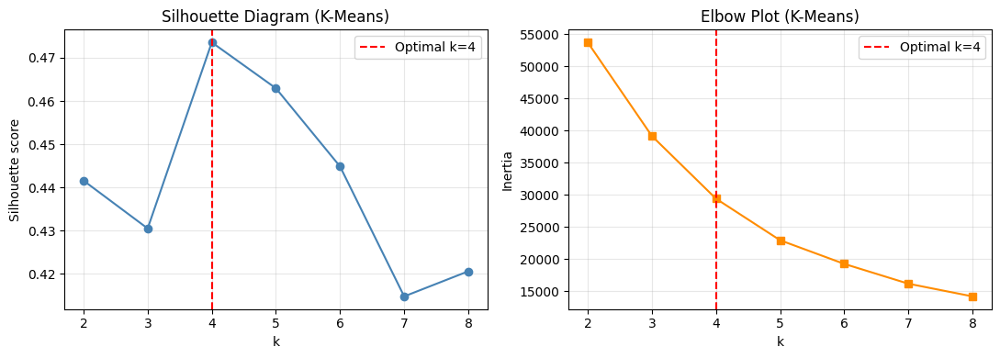

In [25]:
# ── Silhouette + Elbow plots ──────────────────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(list(K_RANGE), sil_scores, 'o-', color='steelblue')
ax1.axvline(K_OPT, color='red', ls='--', label=f'Optimal k={K_OPT}')
ax1.set_xlabel('k'); ax1.set_ylabel('Silhouette score')
ax1.set_title('Silhouette Diagram (K-Means)'); ax1.legend(); ax1.grid(alpha=0.3)

ax2.plot(list(K_RANGE), inertias, 's-', color='darkorange')
ax2.axvline(K_OPT, color='red', ls='--', label=f'Optimal k={K_OPT}')
ax2.set_xlabel('k'); ax2.set_ylabel('Inertia')
ax2.set_title('Elbow Plot (K-Means)'); ax2.legend(); ax2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

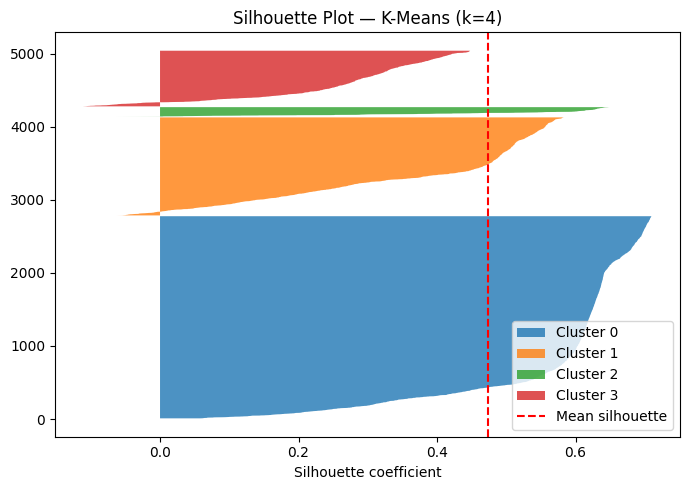

In [26]:
# ── Silhouette sample plot at optimal k ───────────────────────────────────────
km_opt    = KMeans(n_clusters=K_OPT, random_state=RNG, n_init=10)
km_labels = km_opt.fit_predict(X_clust)
sil_vals  = silhouette_samples(X_clust[sil_idx], km_labels[sil_idx])
sub_lab   = km_labels[sil_idx]

fig, ax = plt.subplots(figsize=(7, 5))
y_lower = 10
for k in range(K_OPT):
    vals = np.sort(sil_vals[sub_lab == k])
    ax.fill_betweenx(np.arange(y_lower, y_lower + len(vals)), 0, vals,
                     facecolor=plt.cm.tab10(k), alpha=0.8, label=f'Cluster {k}')
    y_lower += len(vals) + 10
ax.axvline(np.mean(sil_vals), color='red', ls='--', label='Mean silhouette')
ax.set_xlabel('Silhouette coefficient')
ax.set_title(f'Silhouette Plot — K-Means (k={K_OPT})')
ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

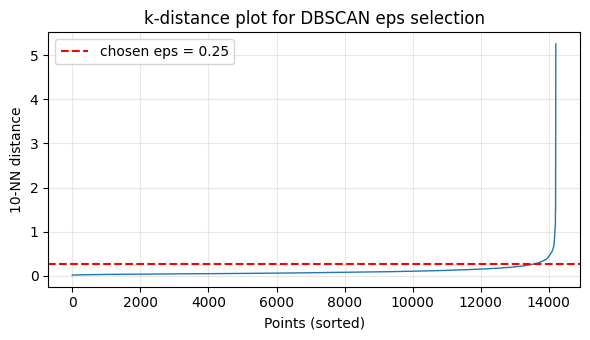

Hierarchical (Ward, k=4)  silhouette=0.4612
DBSCAN(eps=0.25) → 10 clusters, 416 noise pts, silhouette=-0.3548306107266346


In [27]:
# ── DBSCAN eps from k-distance plot; Hierarchical clustering ──────────────────
MIN_SAMPLES = 10
nn    = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X_clust)
dists = np.sort(nn.kneighbors(X_clust)[0][:, -1])
# knee heuristic: eps at the 95th percentile of k-distances
EPS = float(np.percentile(dists, 95))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(dists, lw=1)
ax.axhline(EPS, color='red', ls='--', label=f'chosen eps = {EPS:.2f}')
ax.set_xlabel('Points (sorted)'); ax.set_ylabel(f'{MIN_SAMPLES}-NN distance')
ax.set_title('k-distance plot for DBSCAN eps selection')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

hc        = AgglomerativeClustering(n_clusters=K_OPT, linkage='ward')
hc_labels = hc.fit_predict(X_clust)
sil_hc    = sil(X_clust, hc_labels)
print(f'Hierarchical (Ward, k={K_OPT})  silhouette={sil_hc:.4f}')

db        = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES)
db_labels = db.fit_predict(X_clust)
n_db      = len(set(db_labels)) - (1 if -1 in db_labels else 0)
n_noise   = int(np.sum(db_labels == -1))
if n_db > 1:
    mask   = db_labels != -1
    keep   = np.intersect1d(sil_idx, np.where(mask)[0])
    sil_db = silhouette_score(X_clust[keep], db_labels[keep]) if len(keep) > 100 else np.nan
else:
    sil_db = np.nan
print(f'DBSCAN(eps={EPS:.2f}) → {n_db} clusters, {n_noise} noise pts, silhouette={sil_db}')

SOM grid: 25×25
SOM silhouette=0.2414


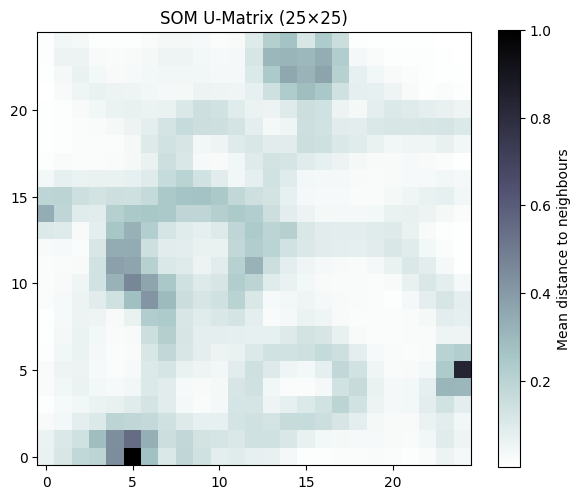

In [28]:
# ── Self-Organising Map ───────────────────────────────────────────────────────
if HAS_MINISOM:
    SIDE = max(5, int(np.ceil(np.sqrt(5 * np.sqrt(X_clust.shape[0])))))
    print(f'SOM grid: {SIDE}×{SIDE}')
    som = MiniSom(SIDE, SIDE, X_clust.shape[1],
                  sigma=1.5, learning_rate=0.5, random_seed=RNG)
    som.random_weights_init(X_clust)
    som.train_random(X_clust, num_iteration=3000, verbose=False)

    weights    = som.get_weights().reshape(-1, X_clust.shape[1])
    km_som     = KMeans(n_clusters=K_OPT, random_state=RNG, n_init=10).fit(weights)
    bmu_list   = [som.winner(x) for x in X_clust]
    som_labels = np.array([km_som.labels_[b[0]*SIDE + b[1]] for b in bmu_list])
    sil_som    = sil(X_clust, som_labels)
    print(f'SOM silhouette={sil_som:.4f}')

    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(som.distance_map().T, cmap='bone_r', origin='lower')
    plt.colorbar(im, ax=ax, label='Mean distance to neighbours')
    ax.set_title(f'SOM U-Matrix ({SIDE}×{SIDE})')
    plt.tight_layout(); plt.show()
else:
    sil_som, som_labels = np.nan, None
    print('SOM skipped — run: pip install minisom')

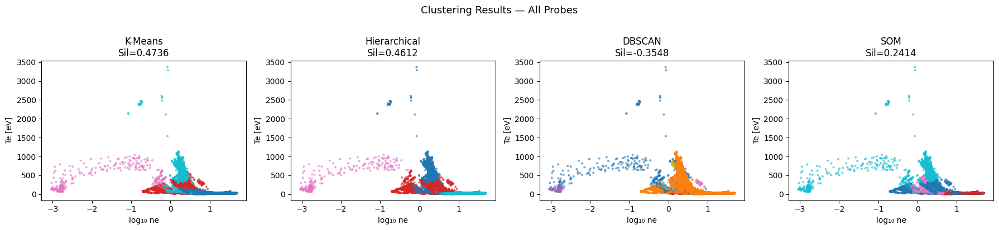

In [29]:
# ── Cluster comparison in feature space ───────────────────────────────────────
label_sets = [
    ('K-Means',      km_labels, max(sil_scores)),
    ('Hierarchical', hc_labels, sil_hc),
    ('DBSCAN',       db_labels, sil_db),
]
if som_labels is not None:
    label_sets.append(('SOM', som_labels, sil_som))

fig, axes = plt.subplots(1, len(label_sets), figsize=(4.5*len(label_sets), 4))
if len(label_sets) == 1:
    axes = [axes]
for ax, (name, labels, s) in zip(axes, label_sets):
    sc = ax.scatter(df_clust['log_ne'], df_clust['Te'],
                    c=labels, cmap='tab10', s=4, alpha=0.5)
    ax.set_xlabel('log₁₀ ne'); ax.set_ylabel('Te [eV]')
    ax.set_title(f'{name}\nSil={s:.4f}' if np.isfinite(s) else f'{name}\nSil=N/A')
plt.suptitle('Clustering Results — All Probes', fontsize=13, y=1.02)
plt.tight_layout(); plt.show()

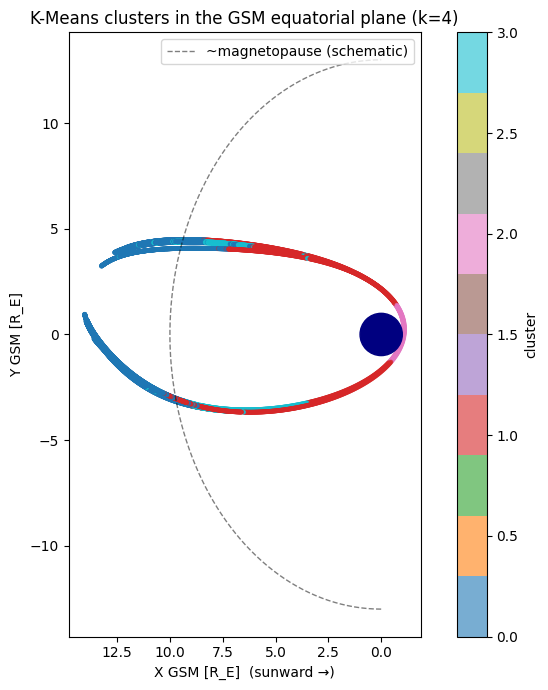

In [30]:
# ── NEW: clusters in physical space (GSM X–Y plane) ───────────────────────────
fig, ax = plt.subplots(figsize=(7.5, 7))
sc = ax.scatter(df_clust['x_re'], df_clust['y_re'], c=km_labels,
                cmap='tab10', s=6, alpha=0.6)
earth = plt.Circle((0, 0), 1, color='navy', zorder=5)
ax.add_patch(earth)
theta = np.linspace(-np.pi/2, np.pi/2, 100)   # rough dayside magnetopause ~10 RE
ax.plot(10*np.cos(theta), 13*np.sin(theta), 'k--', lw=1, alpha=0.5,
        label='~magnetopause (schematic)')
ax.set_xlabel('X GSM [R_E]  (sunward →)')
ax.set_ylabel('Y GSM [R_E]')
ax.set_title(f'K-Means clusters in the GSM equatorial plane (k={K_OPT})')
ax.invert_xaxis()   # convention: Sun to the left in many magnetospheric plots
ax.set_aspect('equal'); ax.legend(loc='upper right')
plt.colorbar(sc, ax=ax, label='cluster')
plt.tight_layout(); plt.show()

In [31]:
# ── Per-cluster physical summary + heuristic region labels ────────────────────
def guess_region(row):
    """Very rough magnetospheric region heuristics — sanity check, not truth."""
    ne_, Te_, B_, R_, beta_ = row['ne'], row['Te'], row['B'], row['R_re'], row['beta_e']
    if np.isfinite(R_) and R_ < 6 and ne_ > 10:
        return 'plasmasphere / inner m-sphere'
    if ne_ > 5 and Te_ < 100:
        return 'magnetosheath-like (dense, cool)'
    if ne_ < 0.1 and (not np.isfinite(beta_) or beta_ < 0.1):
        return 'lobe-like (tenuous, low β)'
    if 0.1 <= ne_ <= 2 and Te_ > 200:
        return 'plasma sheet-like (hot, β≳1)'
    return 'boundary / mixed'

summary = df.loc[df_clust.index].copy()
summary['cluster'] = km_labels
agg = summary.groupby('cluster')[['ne', 'Te', 'B', 'R_re', 'mlt', 'beta_e']].median()
agg['N pts']  = summary.groupby('cluster').size()
agg['region (heuristic)'] = agg.apply(guess_region, axis=1)
print('Median plasma parameters per K-Means cluster:\n')
print(agg.round(3).to_string())
print('\nCross-check the heuristic labels against the X–Y plot above and against')
print('published THEMIS region statistics before trusting them.')

Median plasma parameters per K-Means cluster:

             ne       Te          B    R_re     mlt  beta_e  N pts                region (heuristic)
cluster                                                                                             
0        11.630   29.540     21.672  12.677  12.010   0.410   7896  magnetosheath-like (dense, cool)
1         0.860  110.866    217.766   5.466  14.313   0.001   3785                  boundary / mixed
2         0.092  333.560  17755.028   1.262  19.871   0.000    359        lobe-like (tenuous, low β)
3         1.912  331.183     91.371   8.489  10.444   0.017   2168      plasma sheet-like (hot, β≳1)

Cross-check the heuristic labels against the X–Y plot above and against
published THEMIS region statistics before trusting them.


In [32]:
# ── Clustering league table ───────────────────────────────────────────────────
rows = [
    {'Method': 'K-Means',      'k': K_OPT, 'Silhouette': round(max(sil_scores), 4)},
    {'Method': 'Hierarchical', 'k': K_OPT, 'Silhouette': round(sil_hc, 4)},
    {'Method': 'DBSCAN',       'k': n_db,
     'Silhouette': round(sil_db, 4) if np.isfinite(sil_db) else 'N/A'},
]
if np.isfinite(sil_som):
    rows.append({'Method': 'SOM', 'k': K_OPT, 'Silhouette': round(sil_som, 4)})

clust_league = pd.DataFrame(rows)
print('\n' + '='*40)
print('   CLUSTERING LEAGUE TABLE')
print('='*40)
print(clust_league.to_string(index=False))
print('='*40)


   CLUSTERING LEAGUE TABLE
      Method  k  Silhouette
     K-Means  4      0.4736
Hierarchical  4      0.4612
      DBSCAN 10     -0.3548
         SOM  4      0.2414


---
## 5 — Summary

In [33]:
# ── Auto-filled summary table ─────────────────────────────────────────────────
best_reg_esa = max((r for r in esa_results if r['_model'] is not None),
                   key=lambda r: r['R²'])
pers_r2 = next(r['R²'] for r in esa_results if r['Model'].startswith('Persistence'))
summary_rows = [
    {'Task': 'Regression — log₁₀ ne (ESA)',
     'Best method': best_reg_esa['Model'], 'Metric': f"R² = {best_reg_esa['R²']:.4f}"},
    {'Task': '  vs persistence baseline',
     'Best method': '(previous 30-s value)', 'Metric': f'R² = {pers_r2:.4f}'},
]
if scpot_results is not None:
    best_reg_sp = max((r for r in scpot_results if r['_model'] is not None),
                      key=lambda r: r['R²'])
    summary_rows.append({'Task': 'Regression — log₁₀ ne (scpot2dens)',
                         'Best method': best_reg_sp['Model'],
                         'Metric': f"R² = {best_reg_sp['R²']:.4f}"})
summary_rows += [
    {'Task': 'Classification (Low/Med/High)',
     'Best method': best_clf['Model'],
     'Metric': f"Accuracy = {best_clf['Accuracy']:.4f}"},
    {'Task': 'Clustering',
     'Best method': f'K-Means (k={K_OPT})',
     'Metric': f'Silhouette = {max(sil_scores):.4f}'},
]
if lopo_rows:
    summary_rows.append({'Task': 'Cross-probe generalisation',
                         'Best method': f'LOPO w/ {best_name}',
                         'Metric': f"mean R² = {lopo_df['R²'].mean():.4f}"})
print(pd.DataFrame(summary_rows).to_string(index=False))

                              Task           Best method              Metric
       Regression — log₁₀ ne (ESA)         Random Forest        R² = -0.1243
           vs persistence baseline (previous 30-s value)         R² = 0.9267
Regression — log₁₀ ne (scpot2dens)     Gradient Boosting         R² = 0.9865
     Classification (Low/Med/High)                   kNN   Accuracy = 0.5044
                        Clustering         K-Means (k=4) Silhouette = 0.4736
        Cross-probe generalisation LOPO w/ Random Forest    mean R² = 0.8699


**Discussion points**

- **Physics vs autocorrelation.** How much of v2's high R² survives once the lag
  and ion-density features are removed? The gap between the persistence baseline
  and the best physics-only model is the honest measure of what the models learned.
- **scpot2dens as target vs feature.** The spacecraft potential is *itself* a
  density proxy (that's the whole premise of `scpot2dens`), so a model predicting
  ne from scpot is partly rediscovering that analytic relationship. Is the ML model
  beating the analytic formula? Compare model residuals against
  `log10(ne_scpot) − log10(ne)`.
- **Cross-probe transfer.** If leave-one-probe-out R² is much lower than the
  chronological hold-out, the model is keying on orbit/region differences between
  probes. In 2007 the five THEMIS probes were in a string-of-pearls configuration,
  so their sampled regions overlap heavily — try a 2008–2009 interval where the
  orbits diverge.
- **Do the clusters map to real regions?** Compare the heuristic labels with the
  GSM X–Y plot: dayside compressed-field clusters, tail lobes, plasma sheet
  crossings. βₑ should separate lobe from plasma sheet cleanly.
- **Solar-wind driving.** Do the OMNI features carry importance, or is everything
  local? Try lagging the OMNI inputs by 30–60 min (propagation + response time)
  and see if importance shifts.

**Next steps**

- Longer / multiple intervals (a single day is one orbital geometry and one solar-wind state).
- Event-based splits (train on some days, test on others) — stricter than a single chronological split.
- Compare with MMS or Cluster data via their PySPEDAS load routines for cross-mission validation.